# Lab 2: Epsilon-Greedy vs SoftMax Exploration

**Course:** Reinforcement Learning, Semester 6, Plaksha University

Compares epsilon-greedy (epsilon = 0.01, 0.1) with SoftMax (Boltzmann) action selection (tau = 0.1, 0.5) on the stationary 10-armed testbed: 2,000 runs of 1,000 steps each. Three measures: average reward, % optimal action and average regret (best true mean minus the true mean of the chosen arm).

ε-greedy explores by choosing a random action with probability ε  
Softmax explores by assigning probabilities proportional to estimated Q-values.

Values:
ϵ-greedy: ϵ ∈ {0.01, 0.1}
Softmax: τ ∈ {0.1, 0.5}

In [1]:
import numpy as np
np.random.seed(26)

## Environment

In [2]:
import numpy as np

class MultiArmedBandit:
    def __init__(self, k=10, stationary=True):
        self.k = k
        self.stationary = stationary
        self.q_true = np.random.normal(0, 1, k)
        self.optimal_action = np.argmax(self.q_true)
        
    def step(self, action):
        reward = np.random.normal(self.q_true[action], 1)
        return reward

    def get_optimal_mean(self):
        return np.max(self.q_true)
                


## Agent: SoftMax if tau is given, otherwise epsilon-greedy

In [3]:
class BanditAgent:
    def __init__(self, k=10, epsilon=0.1, tau=None):
        self.k = k
        self.epsilon = epsilon
        self.tau = tau
        self.Q = np.zeros(k)
        self.N = np.zeros(k)

    def select_action(self):
        # Softmax
        if self.tau is not None:
            max_Q = np.max(self.Q)
            exp_vals = np.exp((self.Q - max_Q) / self.tau)
            probs = exp_vals / np.sum(exp_vals)
            return np.random.choice(self.k, p=probs)

        # ε-greedy
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.k)
        return np.argmax(self.Q)

    def update(self, action, reward):
        self.N[action] += 1
        self.Q[action] += (reward - self.Q[action]) / self.N[action]


## Experiment loop

In [4]:
def run_experiments(steps, runs, epsilon=None, tau=None):
    avg_reward = np.zeros(steps)
    optimal_action_pct = np.zeros(steps)
    avg_regret = np.zeros(steps)

    for _ in range(runs):
        bandit = MultiArmedBandit()
        agent = BanditAgent(epsilon=epsilon, tau=tau)
        optimal_mean = bandit.get_optimal_mean()

        for t in range(steps):
            action = agent.select_action()
            reward = bandit.step(action)
            agent.update(action, reward)

            avg_reward[t] += reward
            optimal_action_pct[t] += (action == bandit.optimal_action)
            avg_regret[t] += (optimal_mean - bandit.q_true[action])

    avg_reward /= runs
    optimal_action_pct = (optimal_action_pct / runs) * 100
    avg_regret /= runs

    return avg_reward, optimal_action_pct, avg_regret


In [5]:
steps = 1000
runs = 2000

r_e01, o_e01, reg_e01 = run_experiments(steps, runs, epsilon=0.1)
r_e001, o_e001, reg_e001 = run_experiments(steps, runs, epsilon=0.01)

r_t01, o_t01, reg_t01 = run_experiments(steps, runs, tau=0.1)
r_t05, o_t05, reg_t05 = run_experiments(steps, runs, tau=0.5)


## Results

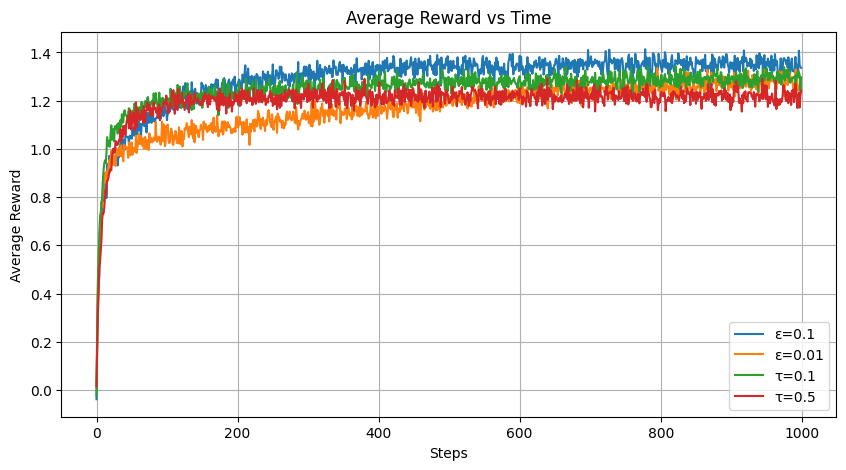

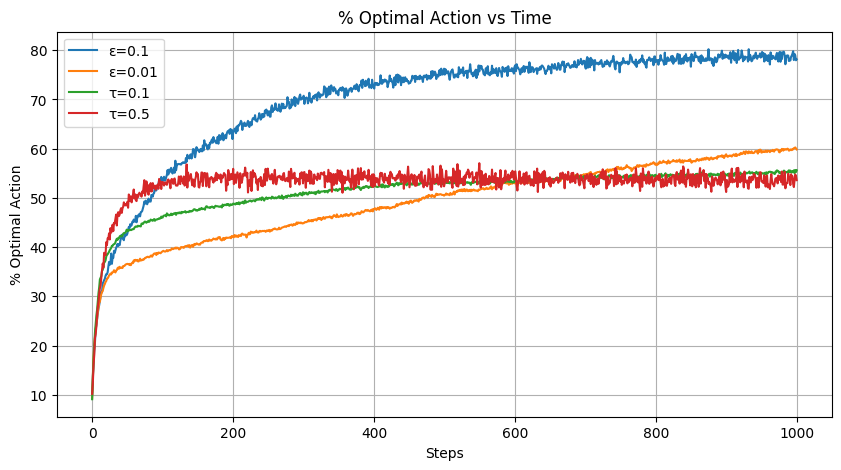

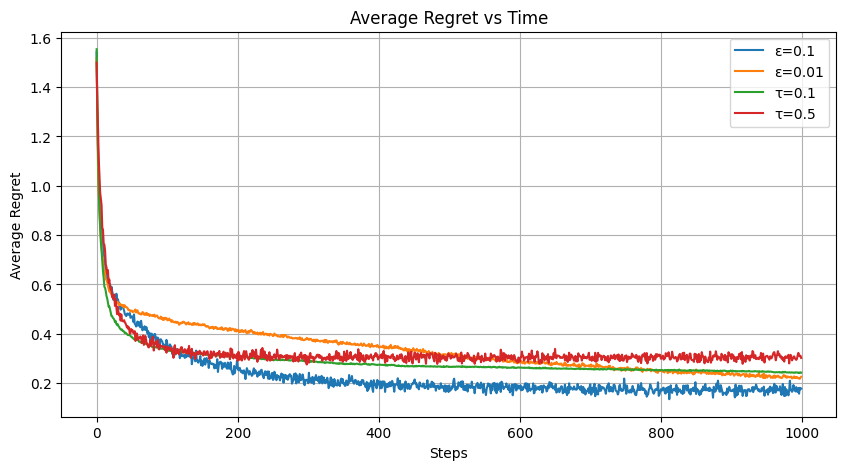

In [6]:
import matplotlib.pyplot as plt

x = np.arange(steps)

# Plot 1: Average Reward
plt.figure(figsize=(10, 5))
plt.plot(x, r_e01, label="ε=0.1")
plt.plot(x, r_e001, label="ε=0.01")
plt.plot(x, r_t01, label="τ=0.1")
plt.plot(x, r_t05, label="τ=0.5")
plt.title("Average Reward vs Time")
plt.xlabel("Steps")
plt.ylabel("Average Reward")
plt.legend()
plt.grid()
plt.show()

# Plot 2: % Optimal Action
plt.figure(figsize=(10, 5))
plt.plot(x, o_e01, label="ε=0.1")
plt.plot(x, o_e001, label="ε=0.01")
plt.plot(x, o_t01, label="τ=0.1")
plt.plot(x, o_t05, label="τ=0.5")
plt.title("% Optimal Action vs Time")
plt.xlabel("Steps")
plt.ylabel("% Optimal Action")
plt.legend()
plt.grid()
plt.show()

# Plot 3: Average Regret
plt.figure(figsize=(10, 5))
plt.plot(x, reg_e01, label="ε=0.1")
plt.plot(x, reg_e001, label="ε=0.01")
plt.plot(x, reg_t01, label="τ=0.1")
plt.plot(x, reg_t05, label="τ=0.5")
plt.title("Average Regret vs Time")
plt.xlabel("Steps")
plt.ylabel("Average Regret")
plt.legend()
plt.grid()
plt.show()


## Answers

**Average Regret Comparison:**  
In the long run, ε-greedy achieves lower average regret than Softmax, indicating faster and more reliable convergence to the optimal arm. Softmax with higher τ shows higher steady-state regret due to continued exploration.

**Effect of τ vs ε on Initial Exploration:**  
Increasing τ in Softmax leads to smoother, value-aware exploration early on, while increasing ε in ε-greedy causes more random, uniform exploration. Softmax explores better initially, but ε-greedy exploits better over time.


## Observations from the plots (values read at step 1,000)

| Method | % optimal action | Average regret |
|---|---|---|
| epsilon = 0.1 | about 79% | about 0.17 |
| epsilon = 0.01 | about 60%, still rising | about 0.22 |
| SoftMax tau = 0.1 | about 55% | about 0.24 |
| SoftMax tau = 0.5 | about 54%, flat after step 100 | about 0.30 |

- **Early on (first 100 steps)** SoftMax reduces regret fastest. It explores in proportion to the estimated values instead of uniformly, so it rarely wastes pulls on clearly bad arms.
- **In the long run** epsilon = 0.1 has the lowest regret and picks the best arm most often. SoftMax with tau = 0.5 stops improving after about 100 steps: with rewards of order 1, tau = 0.5 still gives noticeable probability to close second-best arms, so it keeps paying a constant cost. Smaller tau (0.1) is greedier and does better, but it can lock onto a wrong arm early, which is why it plateaus around 55%.
- epsilon = 0.01 explores so little that it is still improving at step 1,000. Over a longer horizon it would overtake epsilon = 0.1, as in Sutton and Barto's Figure 2.2.